In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from skimage.feature import graycomatrix, graycoprops
from mpl_toolkits.mplot3d import Axes3D

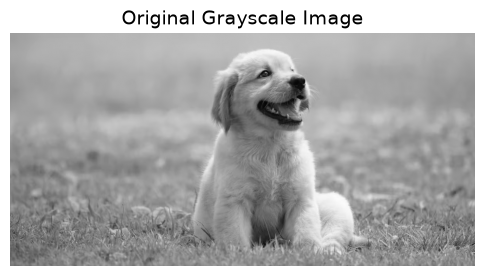

Image Dimensions: (602, 1200)


In [4]:
image = cv2.imread("../Data/Dog.jpg", cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(6, 5))
plt.imshow(image, cmap="gray")
plt.title("Original Grayscale Image", fontsize=14)
plt.axis("off")
plt.show()

print("Image Dimensions:", image.shape)

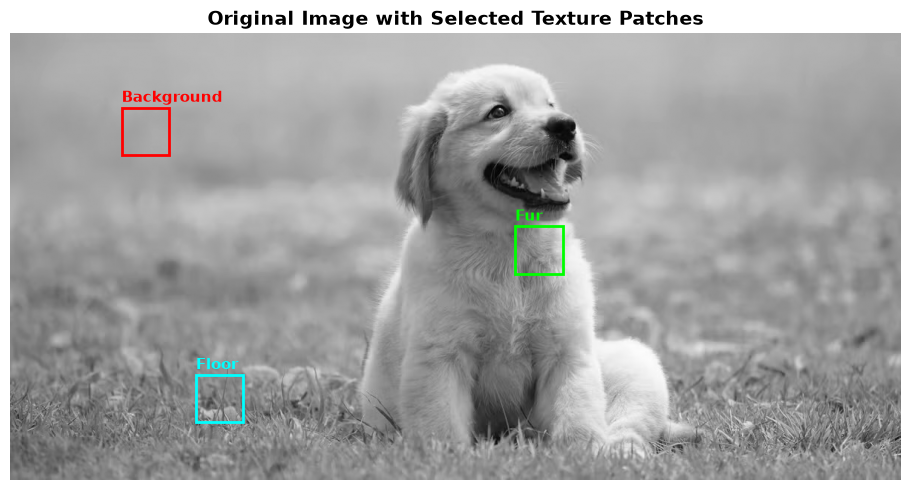

In [11]:
patch_size = 64

patch_locations = {
    "Background": (150, 100),
    "Fur": (680, 260),
    "Floor": (250, 460)
}

patches = {name: image[y:y + patch_size, x:x + patch_size] for name, (x, y) in patch_locations.items()}

fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(image, cmap="gray")
ax.set_title("Original Image with Selected Texture Patches", fontsize=14, fontweight="bold")

colors = ["red", "lime", "cyan"]

for (name, (x, y)), color in zip(patch_locations.items(), colors):
    rect = Rectangle((x, y), patch_size, patch_size, linewidth=2, edgecolor=color, facecolor="none")
    ax.add_patch(rect)
    ax.text(x, y - 8, name, color=color, fontsize=11, fontweight="bold")

ax.axis("off")
plt.tight_layout()
plt.show()

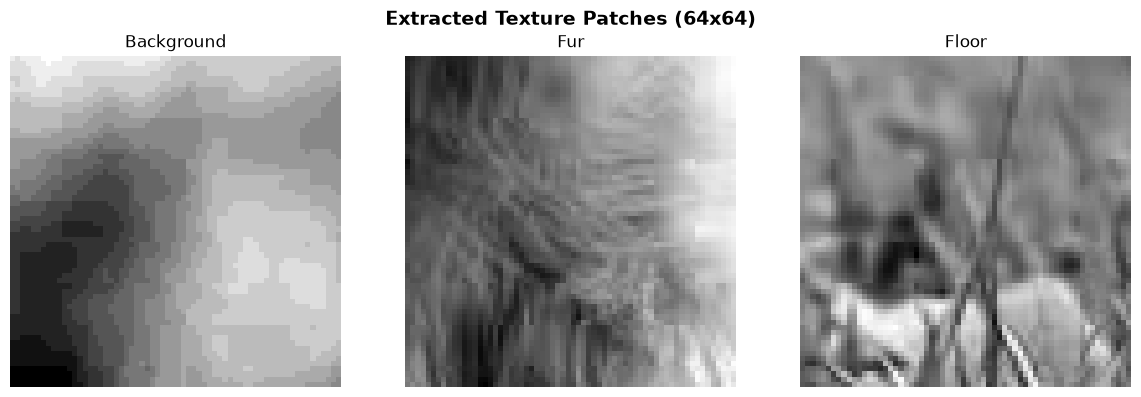

In [12]:
fig, axes = plt.subplots(1, len(patches), figsize=(12, 4))
fig.suptitle(f"Extracted Texture Patches ({patch_size}x{patch_size})", fontsize=14, fontweight="bold")

for idx, (name, patch) in enumerate(patches.items()):
    axes[idx].imshow(patch, cmap="gray")
    axes[idx].set_title(name, fontsize=12)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

In [13]:
def extract_glcm_features(patch: np.ndarray, levels: int = 16) -> tuple[dict[str, float], np.ndarray]:
    quantized = (patch // (256 // levels)).astype(np.uint8)
    glcm = graycomatrix(
        quantized,
        distances=[1],
        angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
        levels=levels,
        symmetric=True,
        normed=True
    )
    props = {
        "Dissimilarity": float(np.mean(graycoprops(glcm, "dissimilarity"))),
        "Correlation": float(np.mean(graycoprops(glcm, "correlation"))),
        "Contrast": float(np.mean(graycoprops(glcm, "contrast"))),
        "Homogeneity": float(np.mean(graycoprops(glcm, "homogeneity"))),
        "Energy": float(np.mean(graycoprops(glcm, "energy")))
    }
    return props, glcm

features = {}
glcm_matrices = {}

for name, patch in patches.items():
    props, glcm = extract_glcm_features(patch)
    features[name] = props
    glcm_matrices[name] = glcm

print("GLCM Texture Features\n")
for name, values in features.items():
    print(name)
    for feature, value in values.items():
        print(f"{feature}: {value:.4f}")
    print()

GLCM Texture Features

Background
Dissimilarity: 0.0125
Correlation: 0.9455
Contrast: 0.0125
Homogeneity: 0.9938
Energy: 0.8712

Fur
Dissimilarity: 0.3517
Correlation: 0.9489
Contrast: 0.3830
Homogeneity: 0.8273
Energy: 0.2717

Floor
Dissimilarity: 0.5214
Correlation: 0.7748
Contrast: 0.8369
Homogeneity: 0.7688
Energy: 0.3430



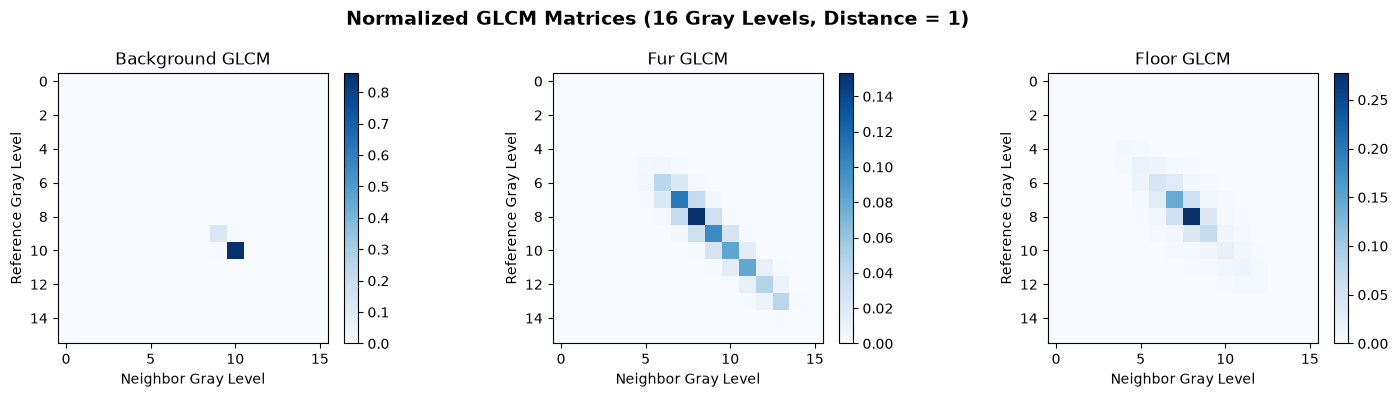

In [14]:
fig, axes = plt.subplots(1, len(patches), figsize=(15, 4))
fig.suptitle("Normalized GLCM Matrices (16 Gray Levels, Distance = 1)", fontsize=14, fontweight="bold")

for idx, (name, glcm) in enumerate(glcm_matrices.items()):
    glcm_avg = np.mean(glcm[:, :, 0, :], axis=-1)
    im = axes[idx].imshow(glcm_avg, cmap="Blues")
    axes[idx].set_title(f"{name} GLCM", fontsize=12)
    axes[idx].set_xlabel("Neighbor Gray Level")
    axes[idx].set_ylabel("Reference Gray Level")
    plt.colorbar(im, ax=axes[idx], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

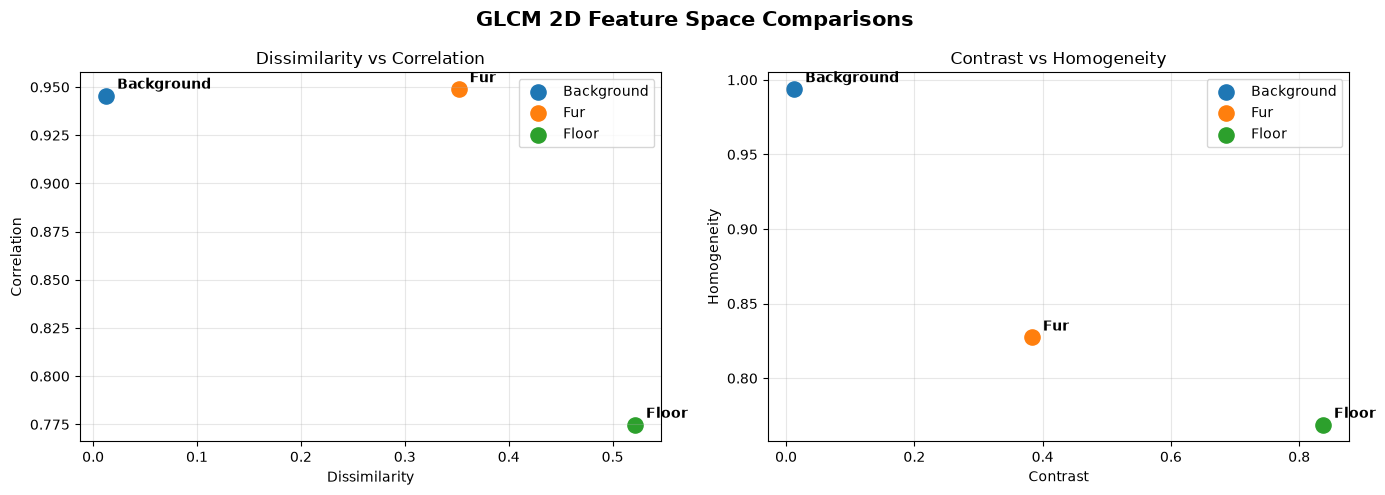

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("GLCM 2D Feature Space Comparisons", fontsize=15, fontweight="bold")

for name, values in features.items():
    axes[0].scatter(values["Dissimilarity"], values["Correlation"], s=120, label=name)
    axes[0].annotate(name, (values["Dissimilarity"], values["Correlation"]), textcoords="offset points", xytext=(8, 5), fontweight="bold")

axes[0].set_xlabel("Dissimilarity")
axes[0].set_ylabel("Correlation")
axes[0].set_title("Dissimilarity vs Correlation", fontsize=12)
axes[0].legend()
axes[0].grid(True, alpha=0.3)

for name, values in features.items():
    axes[1].scatter(values["Contrast"], values["Homogeneity"], s=120, label=name)
    axes[1].annotate(name, (values["Contrast"], values["Homogeneity"]), textcoords="offset points", xytext=(8, 5), fontweight="bold")

axes[1].set_xlabel("Contrast")
axes[1].set_ylabel("Homogeneity")
axes[1].set_title("Contrast vs Homogeneity", fontsize=12)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

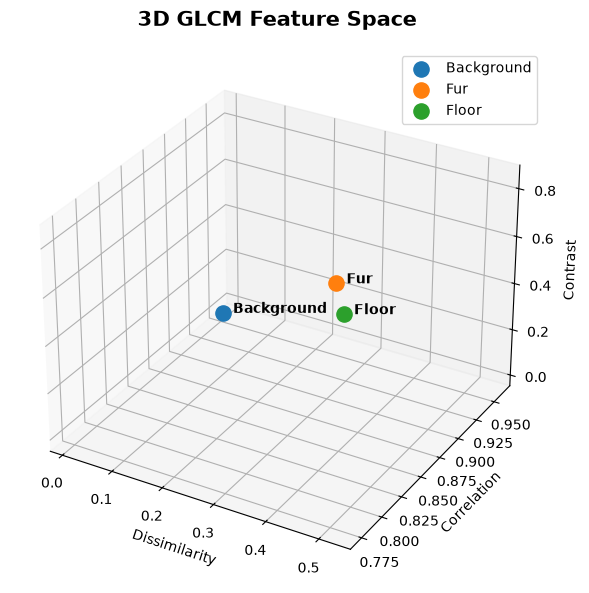

In [10]:
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")
fig.suptitle("3D GLCM Feature Space", fontsize=15, fontweight="bold")

for name, values in features.items():
    ax.scatter(values["Dissimilarity"], values["Correlation"], values["Contrast"], s=120, label=name)
    ax.text(values["Dissimilarity"], values["Correlation"], values["Contrast"], f"  {name}", fontweight="bold")

ax.set_xlabel("Dissimilarity")
ax.set_ylabel("Correlation")
ax.set_zlabel("Contrast")
ax.legend()
plt.tight_layout()
plt.show()